# Week 11 — Visualization II: Queries, movement, and animation

Continue with Census category queries, overlay historical district boundaries, compare taxi pickups and dropoffs, and create an hourly animation. Finish with Philadelphia parking records.

<a href="Visualizing%20Large%20Data-Lec2.ipynb" download>Download notebook</a> · [Visualization I](Visualizing%20Large%20Data-Lec1.html) · [Next: LiDAR processing](lecture-11B.html)

This notebook runs independently; you do not need variables from Lecture 1.


## Before you start

Use **Python (largeviz)** for all three Week 11 sections. Download <a href="environment-viz.yml" download>environment-viz.yml</a> beside the notebooks. In a terminal opened in this lab folder:

```bash
# First time only:
conda env create -f environment-viz.yml
# If largeviz already exists, update it instead:
# conda env update -n largeviz -f environment-viz.yml
conda activate largeviz
python -m ipykernel install --user --name largeviz --display-name "Python (largeviz)"
jupyter lab
```

In VS Code, open the notebook and select **Python (largeviz)**. Run the cells from top to bottom. See the [README](README.md) for setup troubleshooting.


## Download the data first

1. Create a local folder named `week11` and save <a href="Visualizing%20Large%20Data-Lec2.ipynb" download>this notebook</a> and <a href="environment-viz.yml" download>environment-viz.yml</a> there.
2. Create `data/samples/` inside `week11`.
3. Download each file below into that folder. Keep the exact filename. If a link opens in the browser, right-click and choose **Save Link As…**.

| Download | Save locally as |
| --- | --- |
| [census_sample.parquet](data/samples/census_sample.parquet) | `data/samples/census_sample.parquet` |
| [districts_2015.geojson](data/samples/districts_2015.geojson) | `data/samples/districts_2015.geojson` |
| [taxi_sample.parquet](data/samples/taxi_sample.parquet) | `data/samples/taxi_sample.parquet` |
| [parking_sample.csv](data/samples/parking_sample.csv) | `data/samples/parking_sample.csv` |

Open the notebook from `week11` and select **Python (largeviz)**. Paths below are relative to that folder. Files are read locally; no automatic downloads or hidden caches are used.

The files are teaching extracts, not the full billion-point archives or representative population/travel estimates. Census dots have synthetic locations. See [sources and sampling](data/samples/provenance.json). For a full local Parquet dataset, change its filename below to your Parquet folder; keep the lazy Dask workflow.


## 1. Import packages and read Census dots


In [15]:
from pathlib import Path

import numpy as np
import pandas as pd
import dask
import dask.dataframe as dd
import datashader as ds
import datashader.transfer_functions as tf
from datashader.utils import lnglat_to_meters
from colorcet import fire
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# Files saved beside this notebook, following the folder layout above.
DATA = Path("data/samples")
OUT = Path("outputs/viz2")
OUT.mkdir(parents=True, exist_ok=True)
print("Datashader", ds.__version__, "| Dask", dask.__version__)
import json


Datashader 0.16.2 | Dask 2024.5.0


In [16]:
race_labels = {"w": "White", "b": "Black", "a": "Asian", "h": "Hispanic", "o": "Other"}
color_key = {"w": "#4cc9f0", "b": "#ffb703", "a": "#90be6d", "h": "#f28482", "o": "#cdb4db"}
census = dd.read_parquet(DATA / "census_sample.parquet", split_row_groups=True)
census["race"] = census["race"].astype(pd.CategoricalDtype(list(race_labels)))
census.head()

,easting,northing,race
0,-12352377.0,3676244.50,h
1,-12352691.0,3679306.75,h
2,-12352058.0,3677210.50,h
3,-12352007.0,3680322.75,h
4,-12351758.0,3677555.75,h


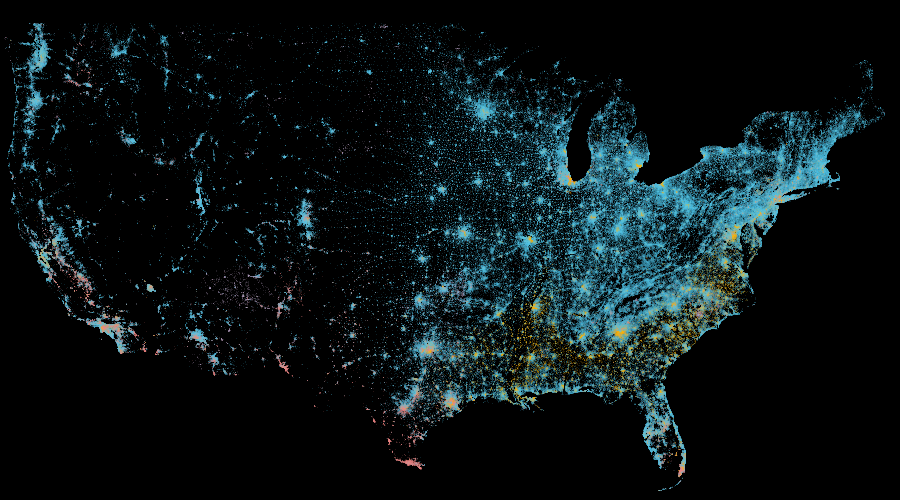

In [17]:
def mercator_extent(lon_bounds, lat_bounds):
    x, y = lnglat_to_meters(lon_bounds, lat_bounds)
    return tuple(x), tuple(y)

usa_x, usa_y = mercator_extent((-125, -66), (24, 50))
census_canvas = ds.Canvas(plot_width=900, plot_height=500, x_range=usa_x, y_range=usa_y)
category_count = census_canvas.points(census, "easting", "northing", agg=ds.count_cat("race"))
census_image = tf.set_background(tf.shade(category_count, color_key=color_key, how="eq_hist"), "black")
display(census_image.to_pil())


## 2. Ask questions of the aggregate

`sel()` selects one category. Boolean comparisons identify pixels meeting a condition. These describe the extract at the chosen pixel size; they are not validated measures of neighborhood diversity or population totals.


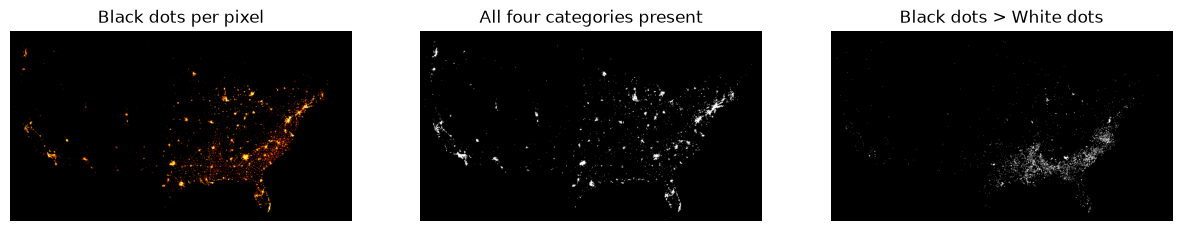

In [18]:
black_dots = category_count.sel(race="b")
all_four = (category_count.sel(race=["w", "b", "a", "h"]) > 0).all(dim="race")
black_exceeds_white = category_count.sel(race="b") > category_count.sel(race="w")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, array, title in zip(
    axes,
    [black_dots, all_four.astype("uint32"), black_exceeds_white.astype("uint32")],
    ["Black dots per pixel", "All four categories present", "Black dots > White dots"],
):
    image = tf.shade(array.where(array > 0), cmap=fire, how="eq_hist")
    ax.imshow(tf.set_background(image, "black").to_pil())
    ax.set_title(title)
    ax.set_axis_off()
plt.show()


## 3. Overlay historical congressional districts

The downloaded GeoJSON is in longitude/latitude. Project each boundary ring to the map's Web Mercator coordinates. An overlay can suggest questions about boundaries; it cannot establish gerrymandering from this sample alone.


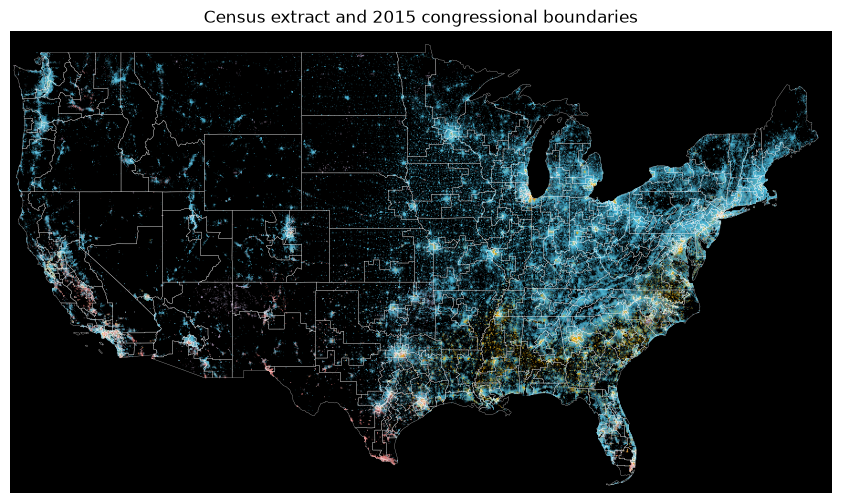

In [19]:
districts = json.loads((DATA / "districts_2015.geojson").read_text())
fig, ax = plt.subplots(figsize=(12, 6))
ax.imshow(census_image.to_pil(), extent=[*usa_x, *usa_y], origin="upper")
for feature in districts["features"]:
    geometry = feature["geometry"]
    polygons = [geometry["coordinates"]] if geometry["type"] == "Polygon" else geometry["coordinates"]
    for polygon in polygons:
        ring = np.asarray(polygon[0])
        x, y = lnglat_to_meters(ring[:, 0], ring[:, 1])
        ax.plot(x, y, color="white", linewidth=0.25, alpha=0.7)
ax.set(xlim=usa_x, ylim=usa_y, title="Census extract and 2015 congressional boundaries")
ax.set_axis_off()
plt.show()


## 4. Compare taxi pickups and dropoffs

Read the taxi extract and aggregate both locations on the same canvas. Subtract signed counts to show where pickups exceed dropoffs.


In [20]:
taxi = dd.read_parquet(DATA / "taxi_sample.parquet", split_row_groups=True)
NYC_X, NYC_Y = mercator_extent((-74.10, -73.70), (40.60, 40.90))
taxi_canvas = ds.Canvas(plot_width=750, plot_height=550, x_range=NYC_X, y_range=NYC_Y)
pickups = taxi_canvas.points(taxi, "pickup_x", "pickup_y", agg=ds.count()).rename({"pickup_x": "x", "pickup_y": "y"})
dropoffs = taxi_canvas.points(taxi, "dropoff_x", "dropoff_y", agg=ds.count()).rename({"dropoff_x": "x", "dropoff_y": "y"})
print("In-view pickups:", int(pickups.sum()), "| in-view dropoffs:", int(dropoffs.sum()))

In-view pickups: 149998 | in-view dropoffs: 149994


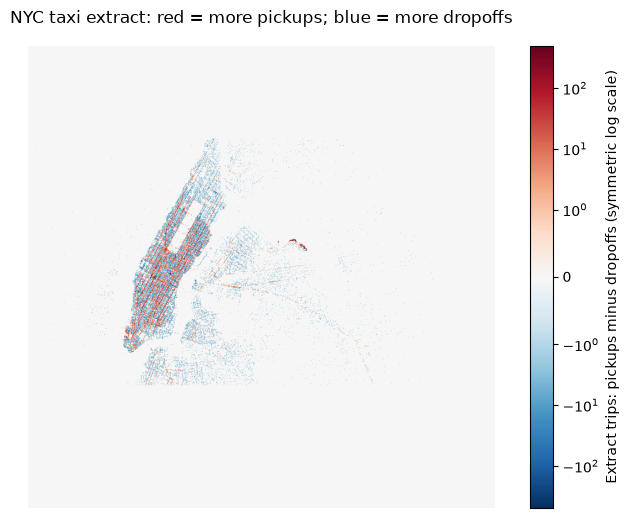

In [21]:
# Subtract signed values: unsigned subtraction would wrap below zero.
balance = pickups.astype("int64") - dropoffs.astype("int64")
from matplotlib.colors import SymLogNorm
limit = max(1, int(np.abs(balance).max()))
fig, ax = plt.subplots(figsize=(9, 6))
plot = ax.imshow(balance, origin="lower", cmap="RdBu_r", norm=SymLogNorm(linthresh=1, vmin=-limit, vmax=limit),
                 extent=[*NYC_X, *NYC_Y])
fig.colorbar(plot, ax=ax, label="Extract trips: pickups minus dropoffs (symmetric log scale)")
ax.set_title("NYC taxi extract: red = more pickups; blue = more dropoffs")
ax.set_axis_off()
plt.show()

### Summarize trips by weekday and hour

Compute a small summary table, then display it as a heatmap. These records cover part of January 2015.


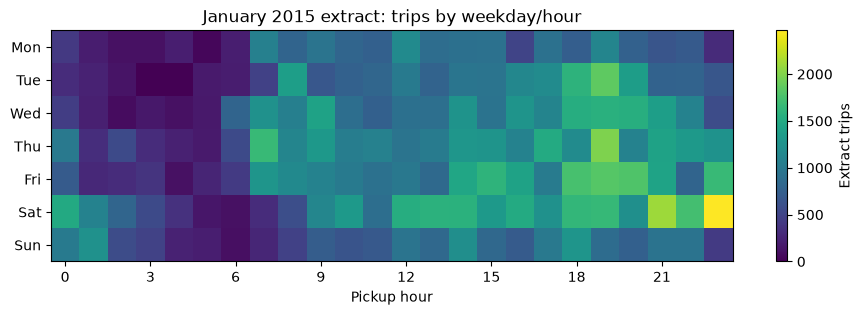

In [22]:
taxi["weekday"] = taxi.tpep_pickup_datetime.dt.dayofweek
hourly_table = taxi.groupby(["weekday", "pickup_hour"]).size().compute().unstack(fill_value=0)
hourly_table = hourly_table.reindex(index=range(7), columns=range(24), fill_value=0)
fig, ax = plt.subplots(figsize=(11, 3))
plot = ax.imshow(hourly_table, aspect="auto", cmap="viridis")
ax.set(yticks=range(7), yticklabels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
       xticks=range(0, 24, 3), xlabel="Pickup hour", title="January 2015 extract: trips by weekday/hour")
fig.colorbar(plot, ax=ax, label="Extract trips")
plt.show()

### Make a 24-hour animation

Count dropoffs by hour and save a GIF. Keep one color scale for every frame so the brightness is comparable.


In [23]:
taxi["dropoff_hour"] = taxi["dropoff_hour"].astype(pd.CategoricalDtype(list(range(24))))
by_hour = taxi_canvas.points(taxi, "dropoff_x", "dropoff_y", agg=ds.count_cat("dropoff_hour"))
max_count = max(2, int(by_hour.max()))
frames = []
from PIL import ImageDraw
for hour in range(24):
    image = tf.set_background(tf.shade(by_hour.sel(dropoff_hour=hour), cmap=fire[40:],
                                       how="log", span=(1, max_count)), "black").to_pil().convert("RGB")
    ImageDraw.Draw(image).text((16, 16), f"{hour:02d}:00 | historical taxi extract", fill="white")
    frames.append(image)
frames[0].save(OUT / "taxi_dropoffs_24h.gif", save_all=True, append_images=frames[1:],
               duration=250, loop=0)
display(HTML('<img src="outputs/viz2/taxi_dropoffs_24h.gif" alt="24-hour taxi drop-off animation">'))

### Add an interactive hour slider

Precompute one image per hour. Bokeh's JavaScript slider works in the exported HTML and does not need a running notebook. Pan/zoom enlarges the fixed images; it does not reaggregate the source points. Live hvPlot/Datashader reaggregation would need an active Python kernel or server.


In [24]:
import base64
import io
from bokeh.embed import file_html
from bokeh.resources import INLINE
from bokeh.layouts import column
from bokeh.models import ColumnDataSource, CustomJS, Slider
from bokeh.plotting import figure
from IPython.display import IFrame

frame_urls = []
for frame in frames:
    buffer = io.BytesIO()
    frame.save(buffer, format="PNG")
    frame_urls.append("data:image/png;base64," + base64.b64encode(buffer.getvalue()).decode())

source = ColumnDataSource(dict(url=[frame_urls[0]]))
plot = figure(width=800, height=580, x_range=(0, 1), y_range=(0, 1),
              title="Taxi dropoffs by hour", tools="pan,wheel_zoom,reset,save")
plot.image_url(url="url", source=source, x=0, y=1, w=1, h=1, anchor="top_left")
plot.axis.visible = False
slider = Slider(start=0, end=23, value=0, step=1, title="Hour of day")
slider.js_on_change("value", CustomJS(args=dict(source=source, frames=frame_urls),
    code="source.data.url = [frames[cb_obj.value]]; source.change.emit();"))
(OUT / "taxi_hour_slider.html").write_text(file_html(column(slider, plot), INLINE, "Taxi hour explorer"))
display(IFrame("outputs/viz2/taxi_hour_slider.html", width=850, height=680))


### A radial view of weekday/hour counts

Use the same small summary table as the rectangular heatmap. Hours run around the circle; rings represent weekdays. This sample covers January 2015, so it cannot support the original lecture's full-year 2016 holiday or blizzard conclusions.


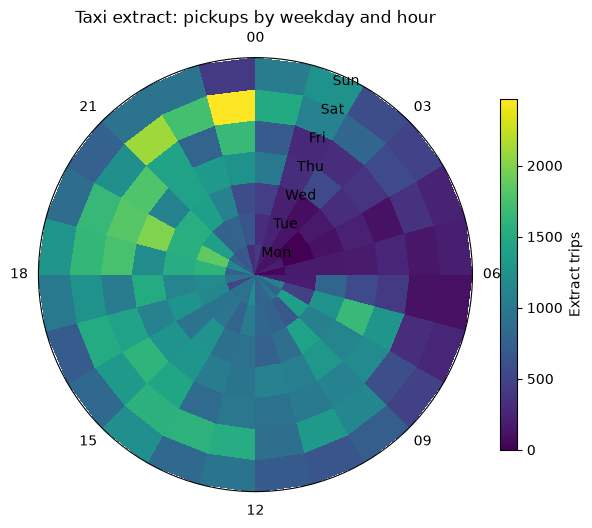

In [25]:
theta = np.linspace(0, 2 * np.pi, 25)
radii = np.arange(8)
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"projection": "polar"})
ax.grid(False)
image = ax.pcolormesh(theta, radii, hourly_table.to_numpy(), cmap="viridis", shading="flat")
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.set_xticks(np.arange(0, 2 * np.pi, np.pi / 4), labels=["00", "03", "06", "09", "12", "15", "18", "21"])
ax.set_yticks(np.arange(7) + 0.5, labels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_title("Taxi extract: pickups by weekday and hour", pad=25)
fig.colorbar(image, ax=ax, label="Extract trips", shrink=0.65)
plt.show()


## 5. Practice: Philadelphia parking records

Read the downloaded CSV lazily. Drop missing values only in the coordinate columns, remove impossible coordinates, and project each partition. Compare maps with different canvas sizes.


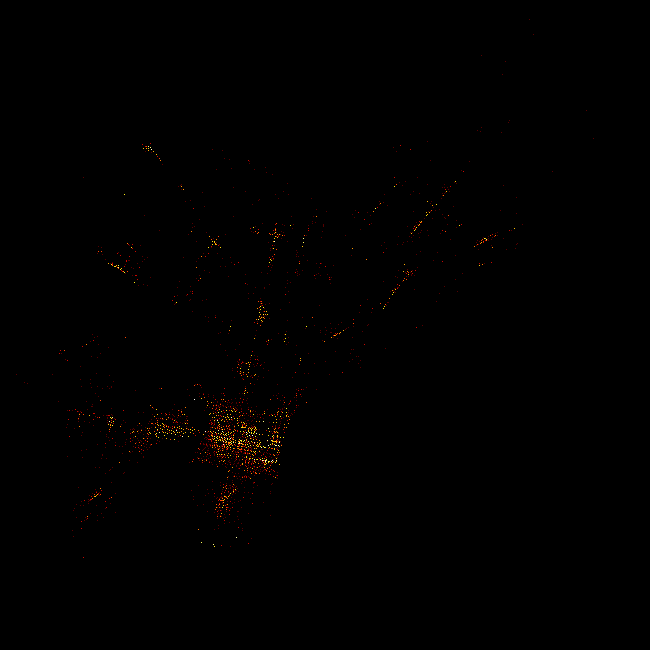

In [26]:
parking = dd.read_csv(DATA / "parking_sample.csv", dtype={"lat": "float64", "lon": "float64"})
parking = parking.dropna(subset=["lat", "lon"])
parking = parking[parking.lat.between(-85, 85) & parking.lon.between(-180, 180)]

def project_parking(partition):
    result = partition.copy()
    result["x"], result["y"] = lnglat_to_meters(result.lon.to_numpy(), result.lat.to_numpy())
    return result

meta = parking._meta.assign(x=pd.Series(dtype="float64"), y=pd.Series(dtype="float64"))
parking_xy = parking.map_partitions(project_parking, meta=meta)
philly_x, philly_y = mercator_extent((-75.28, -74.96), (39.86, 40.14))
parking_canvas = ds.Canvas(plot_width=650, plot_height=650, x_range=philly_x, y_range=philly_y)
parking_counts = parking_canvas.points(parking_xy, "x", "y", agg=ds.count())
parking_image = tf.set_background(tf.shade(parking_counts, cmap=fire[40:], how="eq_hist"), "black")
display(parking_image.to_pil())

## Try it yourself

1. Change the category query to require at least two dots per category. How does the map change?
2. Compare taxi pickups and dropoffs around an airport or a different city extent.
3. Use the exported hourly slider without running Python. Explain why it can change frames but cannot recompute density at a new resolution.
4. Change the parking map extent and canvas size.

**Next:** [LiDAR processing](lecture-11B.html) turns point clouds into smoothed DSM rasters using the same `largeviz` environment.
